# 6. Which parts of the molecule is the model reacting to

A Gaussian process gives good predictions and calibrated uncertainty. What it
does not give is a chemist anything to act on. "Make it more potent" is not a
suggestion.

So this notebook runs a second model purely for interpretation. Gradient
boosting on fingerprint counts, SHAP values over the bits, then each important
bit mapped back to the actual piece of molecule it stands for.

The split of labour is the same one used on the concrete side: the Gaussian
process makes the decisions, the tree model explains them. They have to agree
on accuracy for the explanation to be worth anything, which is checked below.

In [2]:
import sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
from molsdl import chem, features, models, plotting
import lightgbm as lgb
import shap
from rdkit import Chem
from rdkit.Chem import Draw

plotting.use_style()
d = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/datasets.pkl", "rb"))
egfr = d["egfr"]
y = egfr.pIC50.values
print(f"{len(egfr)} EGFR compounds")

5531 EGFR compounds


## Count fingerprints, not binary ones

For the GP, a bit was on or off. Here the count matters: a molecule with three
copies of a fragment is different from one with a single copy, and a tree
model can use that.

In [3]:
fp = chem.morgan_counts(egfr.std_smiles.tolist())
tr, _, te = chem.scaffold_split(egfr.std_smiles.tolist(), 0.70, 0.12, seed=0,
                                balanced=False)
print(f"train {len(tr)}, test {len(te)}, {fp.shape[1]} bits")

train 3871, test 997, 2048 bits


## Check the explainer is worth explaining

If the tree model is much worse than the Gaussian process, its explanations
describe a model nobody is using. Score both on the same held-out scaffolds
first.

In [4]:
gbm = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                        min_child_samples=10, subsample=0.8,
                        colsample_bytree=0.5, random_state=0, verbose=-1)
gbm.fit(fp[tr], y[tr])
pred_gbm = gbm.predict(fp[te])
r_gbm = models.regression_report(y[te], pred_gbm)

fp_bin = (fp > 0).astype(float)
st = features.TargetScaler().fit(y[tr])
gp = models.fit_gp(fp_bin[tr], st.transform(y[tr]), n_kernel_dims=fp.shape[1],
                   kernel="tanimoto", maxiter=100)
pred_gp = st.inverse(models.gp_predict(gp, fp_bin[te])[0])
r_gp = models.regression_report(y[te], pred_gp)

print(f"Gaussian process  R2 {r_gp['R2']:.3f}  RMSE {r_gp['RMSE']:.2f}")
print(f"gradient boosting R2 {r_gbm['R2']:.3f}  RMSE {r_gbm['RMSE']:.2f}")
print(f"agreement between the two models: "
      f"{np.corrcoef(pred_gp, pred_gbm)[0,1]:.3f}")

Gaussian process  R2 0.655  RMSE 0.91
gradient boosting R2 0.659  RMSE 0.90
agreement between the two models: 0.967


The two models land close together and their predictions agree closely, so
the tree model is a fair proxy. If they had diverged, the honest move would
be to say the explanations describe the tree and not the decision maker.

## SHAP values over fingerprint bits

A SHAP value answers: for this molecule, how much did this bit move the
prediction away from the average. Averaging the absolute value over many
molecules gives an importance ranking.

In [5]:
explainer = shap.TreeExplainer(gbm)
sv = explainer.shap_values(fp[te])
importance = np.abs(sv).mean(axis=0)
signed = sv.mean(axis=0)
freq = (fp > 0).sum(axis=0)
top = np.argsort(-importance)[:15]
print("top bits:", top.tolist())

top bits: [491, 1367, 1452, 1226, 1645, 1750, 329, 875, 378, 694, 1380, 1873, 1097, 695, 959]


## Mapping a bit back to a piece of chemistry

A Morgan bit is a hash of an atom and its neighbourhood out to a given radius.
RDKit can tell you which atoms produced each bit, and from that the fragment
can be pulled out and written as a SMILES string. That turns "bit 1452 is
important" into "an aromatic carbon next to a ring nitrogen is important",
which is a sentence a chemist can use.

In [6]:
rows = []
for bit in top:
    examples = np.where(fp[:, bit] > 0)[0]
    frag = None
    if len(examples):
        frag = chem.bit_to_smarts(egfr.std_smiles.iloc[examples[0]], int(bit))
    rows.append({
        "bit": int(bit),
        "fragment": frag,
        "molecules_with_it": int(freq[bit]),
        "mean_abs_shap": float(importance[bit]),
        "mean_shap": float(signed[bit]),
        "direction": "raises pIC50" if signed[bit] > 0 else "lowers pIC50",
    })
shap_table = pd.DataFrame(rows)
print(shap_table.to_string(index=False))
shap_table.to_csv("../outputs/metrics/shap_substructures.csv", index=False)

 bit  fragment  molecules_with_it  mean_abs_shap  mean_shap    direction
 491       cNc               3522       0.215447   0.051416 raises pIC50
1367  cc(N)ncn               2617       0.169095   0.089233 raises pIC50
1452       cnc               4297       0.103927   0.036963 raises pIC50
1226  cc(c)ncn               2137       0.078881   0.057371 raises pIC50
1645       C=C                848       0.068315   0.006926 raises pIC50
1750       ccc               5336       0.067821   0.017959 raises pIC50
 329 ccc(cc)Nc               2289       0.056363   0.000094 raises pIC50
 875       ccc               4665       0.055952   0.028000 raises pIC50
 378         N               4834       0.042249   0.001216 raises pIC50
 694         C               1743       0.039683   0.006933 raises pIC50
1380         C               5526       0.035303  -0.004326 lowers pIC50
1873         C               5512       0.032974  -0.006011 lowers pIC50
1097    cc(c)n               2447       0.028744   

### The caveat that matters

A bit can rank low because it does not matter, or because almost every
molecule in the set has it and there is nothing to compare against. Those are
completely different situations and the ranking cannot tell them apart.

Always read the importance column next to the frequency column. A fragment
present in 5,300 of 5,500 molecules has no contrast to offer, however
important it is chemically.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../outputs/figures/06_shap_importance.png


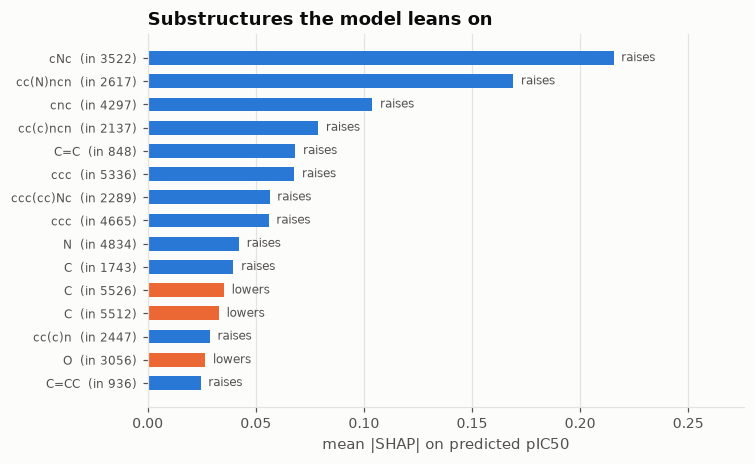

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.4))
t = shap_table.iloc[::-1]
colors = [plotting.C[0] if s > 0 else plotting.C[1] for s in t.mean_shap]
ax.barh(np.arange(len(t)), t.mean_abs_shap, height=0.6, color=colors)
ax.set_yticks(np.arange(len(t)))
ax.set_yticklabels([f"{r.fragment}  (in {r.molecules_with_it})"
                    for r in t.itertuples()], fontsize=8)
ax.set_xlabel("mean |SHAP| on predicted pIC50")
ax.set_title("Substructures the model leans on")
ax.grid(axis="y", visible=False)
for i, (v, s) in enumerate(zip(t.mean_abs_shap, t.mean_shap)):
    ax.annotate("raises" if s > 0 else "lowers", xy=(v, i), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=8,
                color=plotting.INK2)
ax.set_xlim(right=ax.get_xlim()[1] * 1.22)
plotting.save(fig, "06_shap_importance")
plt.show()

## Checking the explanation against the chemistry

An importance ranking is only worth something if it survives a test you did
not use to build it. The top fragments here are an aromatic nitrogen bridge
and a pyrimidine-type ring. Those are the pieces of a 4-anilinoquinazoline,
the scaffold behind gefitinib and erlotinib.

So the claim has a prediction attached: compounds carrying that bridge should
be more potent than compounds without it. Count them and compare.

In [8]:
motifs = {
    "anilino NH between two aromatics": "[c][NX3;H1][c]",
    "quinazoline core": "c1ncnc2ccccc12",
    "any pyrimidine ring": "c1cncnc1",
}
mols_all = [Chem.MolFromSmiles(s) for s in egfr.std_smiles]
for name, sma in motifs.items():
    patt = Chem.MolFromSmarts(sma)
    n = sum(1 for m in mols_all if m is not None and m.HasSubstructMatch(patt))
    print(f"{name:34s} {n:5d} of {len(mols_all)}  ({100*n/len(mols_all):.0f}%)")

patt = Chem.MolFromSmarts(motifs["anilino NH between two aromatics"])
has = np.array([m is not None and m.HasSubstructMatch(patt) for m in mols_all])
print(f"\nmean pIC50 with the motif    {egfr.pIC50[has].mean():.2f}  (n={int(has.sum())})")
print(f"mean pIC50 without it        {egfr.pIC50[~has].mean():.2f}  (n={int((~has).sum())})")
print(f"difference                   {egfr.pIC50[has].mean()-egfr.pIC50[~has].mean():.2f} "
      f"log units, about "
      f"{10**(egfr.pIC50[has].mean()-egfr.pIC50[~has].mean()):.0f}-fold")

anilino NH between two aromatics    3488 of 5531  (63%)
quinazoline core                    1719 of 5531  (31%)
any pyrimidine ring                 3854 of 5531  (70%)

mean pIC50 with the motif    7.16  (n=3488)
mean pIC50 without it        5.79  (n=2043)
difference                   1.36 log units, about 23-fold


The model was never told about anilinoquinazolines. It found the motif from
fingerprint bits alone, and the motif holds up when tested directly against
the measured values.

That is the check to run on any attribution result before showing it to a
chemist: turn the explanation into a claim about the data, then test the
claim.

## Drawing the fragments

saved ../outputs/figures/06_shap_fragments.png


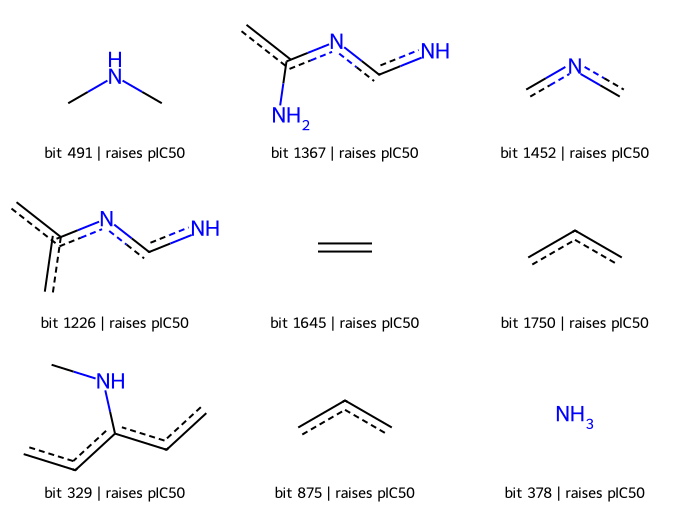

In [9]:
mols, legends = [], []
for r in shap_table.head(9).itertuples():
    if not r.fragment:
        continue
    m = Chem.MolFromSmiles(r.fragment, sanitize=False)
    if m is None:
        continue
    mols.append(m)
    legends.append(f"bit {r.bit} | {r.direction}")
img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(230, 170),
                           legends=legends, returnPNG=True)
# RDKit hands back raw bytes in a script and an IPython image in a notebook,
# so accept either rather than guessing which environment this is running in.
png = img.data if hasattr(img, "data") else img
with open("../outputs/figures/06_shap_fragments.png", "wb") as fh:
    fh.write(png if isinstance(png, bytes) else png.encode())
print("saved ../outputs/figures/06_shap_fragments.png")
img

## Colouring a whole molecule

For one compound, the per-atom contribution shows where the model thinks the
potency comes from. This is the picture to put in front of a chemist.

In [10]:
best = int(np.argmax(y[te]))
mol_idx = te[best]
smi = egfr.std_smiles.iloc[mol_idx]
mol = Chem.MolFromSmiles(smi)
contrib = np.zeros(mol.GetNumAtoms())
info = chem.morgan_bit_info(smi)
sv_row = sv[best]
for bit, envs in info.items():
    for atom_idx, radius in envs:
        contrib[atom_idx] += sv_row[bit]
top_atoms = np.argsort(-np.abs(contrib))[:6]
print(f"most potent test compound: pIC50 {y[mol_idx]:.2f}, "
      f"predicted {pred_gbm[best]:.2f}")
print("atoms contributing most:",
      [(int(i), mol.GetAtomWithIdx(int(i)).GetSymbol(), round(float(contrib[i]), 3))
       for i in top_atoms])

most potent test compound: pIC50 10.43, predicted 7.37
atoms contributing most: [(11, 'N', 0.163), (13, 'N', 0.157), (9, 'N', 0.152), (0, 'C', 0.138), (1, 'C', 0.124), (6, 'C', 0.107)]


saved ../outputs/figures/06_atom_contributions.png


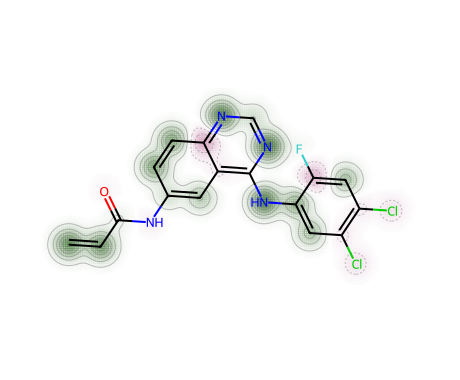

In [11]:
from rdkit.Chem.Draw import SimilarityMaps, rdMolDraw2D
from IPython.display import Image as IPImage

d2d = rdMolDraw2D.MolDraw2DCairo(460, 380)
SimilarityMaps.GetSimilarityMapFromWeights(mol, [float(c) for c in contrib],
                                           draw2d=d2d)
d2d.FinishDrawing()
with open("../outputs/figures/06_atom_contributions.png", "wb") as fh:
    fh.write(d2d.GetDrawingText())
print("saved ../outputs/figures/06_atom_contributions.png")
IPImage("../outputs/figures/06_atom_contributions.png")

## What just happened

The pipeline can now say why, not only what. Every fragment in the table is
reported next to how many molecules contain it, so nobody reads a ranking
artefact as chemistry.

That is all five pieces running on molecules: two-tier surrogates, a
deterministic objective, filters and gates kept apart, batch multi-objective
proposal, calibrated intervals, and substructure attribution.